# Titanic Survival Prediction – Data Cleaning Project

**Mini Project 1 – Data Cleaning and Preprocessing**

### Objectives
- Load the Titanic dataset using Pandas.
- Summarize the dataset using `.info()` and `.describe()`.
- Handle missing values using median/mode imputation.
- Encode categorical variables using `LabelEncoder` and `OneHotEncoder`.
- Visualize the age distribution using Matplotlib.
- Export the cleaned dataset as a new CSV file.


## 1. Import Required Libraries

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OneHotEncoder


## 2. Load the Titanic Dataset

In [36]:
# Load the Titanic dataset
df = pd.read_csv("Titanic-Dataset-selected-columns.csv")

# Display the first five rows
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Basic Dataset Information

The `.info()` function shows the number of rows, columns, data types, and non-null values.

In [37]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 4. Descriptive Statistics

The `.describe()` function provides statistical information such as count, mean, standard deviation, minimum, maximum and quartile values.

In [38]:
df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 5. Check Missing Values

In [39]:
# Count missing values in each column
df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 6. Handle Missing Data

- `Age` contains missing values, so the **median** is used for imputation.
- `Embarked` contains a small number of missing values, so the **mode** is used.
- `Cabin` contains many missing values, so it is removed from the cleaned dataset.

In [40]:
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [41]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [42]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [43]:
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [44]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
for col in df.columns:
    print(repr(col))

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (891, 12)

Column names:
'PassengerId'
'Survived'
'Pclass'
'Name'
'Sex'
'Age'
'SibSp'
'Parch'
'Ticket'
'Fare'
'Cabin'
'Embarked'

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [45]:
cleaned = df.copy()

# Median imputation for Age
cleaned['Age'] = cleaned['Age'].fillna(cleaned['Age'].median()
)

# Mode imputation for Embarked
cleaned['Embarked'] = cleaned['Embarked'].fillna(cleaned['Embarked'].mode()[0]
)

# Remove Cabin column
cleaned = cleaned.drop(columns=['Cabin'])

# Check remaining missing values
cleaned.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

## 7. Encode Sex Using LabelEncoder

`LabelEncoder` converts the two categories in the `Sex` column into numerical values.

In [46]:
sex_encoder = LabelEncoder()

cleaned["Sex"] = sex_encoder.fit_transform(cleaned["Sex"])

print("Encoding:", dict(zip(sex_encoder.classes_, sex_encoder.transform(sex_encoder.classes_))))
cleaned[["Sex"]].head()


Encoding: {'female': np.int64(0), 'male': np.int64(1)}


,Sex
0,1
1,0
2,0
3,0
4,1


## 8. Encode Embarked Using OneHotEncoder

One-hot encoding creates separate binary columns for the different embarkation ports.

In [47]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

embarked_encoded = ohe.fit_transform(cleaned[["Embarked"]])
embarked_cols = ohe.get_feature_names_out(["Embarked"])

embarked_df = pd.DataFrame(
    embarked_encoded,
    columns=embarked_cols,
    index=cleaned.index
)

cleaned = pd.concat(
    [cleaned.drop(columns=["Embarked"]), embarked_df],
    axis=1
)

cleaned.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,0.0,0.0,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,1.0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,0.0,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,0.0,0.0,1.0
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,0.0,0.0,1.0


## 9. Visualize Age Distribution

The histogram shows the distribution of passenger ages in the original Titanic dataset.

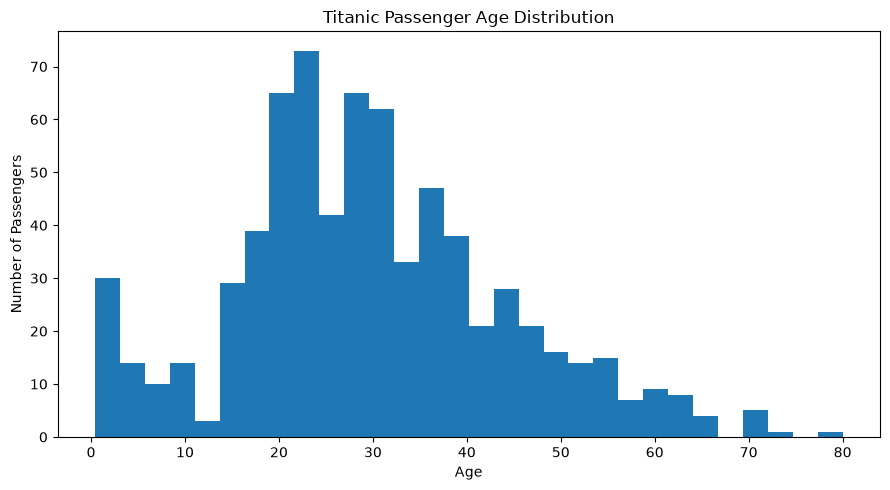

In [48]:
plt.figure(figsize=(9, 5))
plt.hist(df["Age"].dropna(), bins=30)
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.title("Titanic Passenger Age Distribution")
plt.tight_layout()
plt.show()


## 10. Final Cleaned Dataset

In [49]:
print("Final shape:", cleaned.shape)
print("\nMissing values after cleaning:")
print(cleaned.isnull().sum())

cleaned.head()


Final shape: (891, 13)

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
dtype: int64


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,0.0,0.0,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,1.0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,0.0,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,0.0,0.0,1.0
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,0.0,0.0,1.0


## 11. Export Cleaned Dataset as CSV

In [50]:
# Save the cleaned dataset
cleaned.to_csv("Titanic_Cleaned_Dataset.csv", index=False)

print("Cleaned dataset saved successfully as Titanic_Cleaned_Dataset.csv")


Cleaned dataset saved successfully as Titanic_Cleaned_Dataset.csv


## 12. Project Summary

### Completed Tasks
1. Loaded the Titanic dataset using Pandas.
2. Used `.info()` and `.describe()` for basic dataset analysis.
3. Handled missing `Age` values using median imputation.
4. Handled missing `Embarked` values using mode imputation.
5. Removed the highly incomplete `Cabin` column.
6. Encoded `Sex` using `LabelEncoder`.
7. Encoded `Embarked` using `OneHotEncoder`.
8. Created an age distribution visualization using Matplotlib.
9. Exported the final cleaned dataset as `Titanic_Cleaned_Dataset.csv`.

**Final cleaned dataset:** 891 rows × 13 columns.
